<a href="https://colab.research.google.com/github/qtrong0205/plant-care-ai-service/blob/main/classification/training/train_plant_disease_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Plant Care - Classification

In [1]:
from pathlib import Path

%cd /content
if not Path("/content/plant-care-ai-service").exists():
    !git clone https://github.com/qtrong0205/plant-care-ai-service.git
else:
    %cd /content/plant-care-ai-service
    !git pull
%cd /content/plant-care-ai-service/classification/training

/content
Cloning into 'plant-care-ai-service'...
remote: Enumerating objects: 126, done.
remote: Counting objects: 100% (126/126), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 126 (delta 33), reused 87 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (126/126), 13.99 MiB | 17.45 MiB/s, done.
Resolving deltas: 100% (33/33), done.
/content/plant-care-ai-service/classification/training


## 1. Problem Definition

- 1.1. Objective

  The objective of this project is to build a deep learning model that automatically classifies plant diseases from leaf images. The trained model will be deployed as an **ONNX model** in a FastAPI service to provide real-time disease diagnosis for the Plant Care Assistant application.

- 1.2. Dataset

  The model is trained on the **PlantVillage** dataset, which contains approximately 54,000 images across 38 classes covering 14 plant species and their disease categories. To accelerate experimentation and hyperparameter tuning, the initial training will use only 20% of the training dataset (approximately 10,000 images). After selecting the best configuration, the final model will be trained on the full dataset.

- 1.3. Evaluation Metrics

  Model performance will be evaluated using Accuracy, Precision, Recall, F1-score, and the Confusion Matrix.

## 2. Import libraries and Setup device agnostic code

In [2]:
import os
import torch
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path
from torch import nn
from tqdm.auto import tqdm

In [3]:
# Device agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## 3. Load & Explore Data



### 3.1. Download and unzip data

In [4]:
from pathlib import Path

DATA_DIR = Path("data/plantvillage dataset/color")

if DATA_DIR.exists() and any(DATA_DIR.iterdir()):
    print(f"Dataset already exist at '{DATA_DIR}', download skipped.")
else:
    print("Downloading data from Kaggle...")
    !kaggle datasets download -d abdallahalidev/plantvillage-dataset
    !unzip -q plantvillage-dataset.zip -d data/
    print("Downloaded and unziped.")

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:14<00:00, 156MB/s] 

Downloaded and unziped.


In [5]:
from split_dataset import split_dataset

SPLIT_PATH = Path("data/split")
train_path = Path("data/split/train")
test_path = Path("data/split/test")

if train_path.exists() and test_path.exists() and len(list(train_path.iterdir())) == 38:
    print("Already splitted")
else:
    split_dataset(
        source_dir="data/plantvillage dataset/color",
        output_dir=SPLIT_PATH,
        train_ratio=0.8,
    )

Dataset successfully split into 'data/split'.


### 3.2. Create a Custom `ImageDataset` Class

In this section, we implement a custom `ImageDataset` class that accepts the dataset directory, image transformations, and a subset ratio. The `subset_ratio` parameter allows loading only a specified percentage of the original dataset, enabling faster experimentation and model training.

The implementation of the `ImageDataset` class is available in the project repository:

> **GitHub:** https://github.com/qtrong0205/plant-care-ai-service/blob/main/classification/training/data_setup.py

In [6]:
from data_setup import ImageDataset

# Create a dataset with custom ImageDataset
train_dataset = ImageDataset(
    targ_dir=train_path,
    transform=None,
    subset_ratio=0.2,
    seed=42,
)
test_dataset = ImageDataset(
    targ_dir=test_path,
    transform=None,
    subset_ratio=0.2,
    seed=42,
)

print(f"Number of classes in train dataset: {len(train_dataset.classes)}")
print(f"Number of images in train dataset: {len(train_dataset)}")
print(f"Number of classes in test dataset: {len(test_dataset.classes)}")
print(f"Number of images in test dataset: {len(test_dataset)}")

Number of classes in train dataset: 38
Number of images in train dataset: 8673
Number of classes in test dataset: 38
Number of images in test dataset: 2165


In [7]:
from data_setup import find_classes

class_names, class_to_idx = find_classes(train_path)
class_names

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_

### 3.3. Visualize an image

Random image path: data/split/train/Corn_(maize)___healthy/9d37aa23-994e-41b8-8f4c-1e11a05506cf___R.S_HL 8046 copy.jpg
Image class: Corn_(maize)___healthy
Image height: 256
Image width: 256


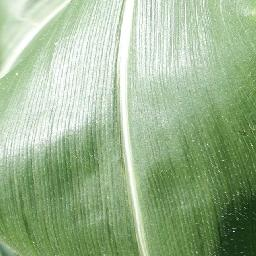

In [8]:
import random
from PIL import Image

# Set seed
# random.seed(42)

# 1. Get all image paths (* means "any combination")
image_path_list = list(SPLIT_PATH.glob("*/*/*.jpg"))

# 2. Get random image path
random_image_path = random.choice(image_path_list)

# 3. Get image class from path name (the image class is the name of the directory where the image is stored)
image_class = random_image_path.parent.stem

# 4. Open image
img = Image.open(random_image_path)

# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

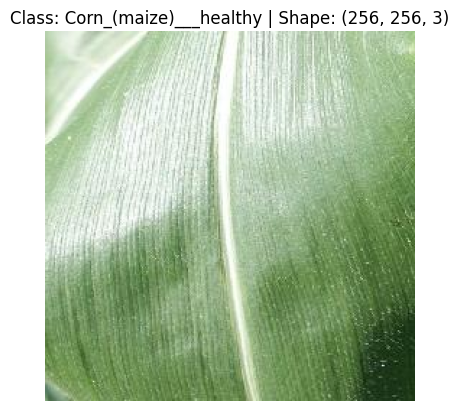

In [9]:
# Turn image into numpy array
img_as_array = np.asarray(img)

plt.imshow(img_as_array)
plt.title(f"Class: {image_class} | Shape: {img_as_array.shape}")
plt.axis(False)

### 3.4. Create DataLoaders

In this section, we recreate the training and testing datasets by applying the appropriate image transformations. We then create `DataLoader` objects for each dataset to enable efficient batch loading, shuffling, and data iteration during model training and evaluation.

In [10]:
import os
from data_setup import create_transform
from data_setup import create_dataloader

NUM_WORKERS = os.cpu_count()
BATCH_SIZE = 32

# Create train and test transform
train_transform = create_transform(size=(224, 224), train=True)
test_transform = create_transform(size=(224, 224), train=False)

# Create train and test dataset
train_dataset = ImageDataset(targ_dir=train_path, transform=train_transform, subset_ratio=0.2, seed=42)
test_dataset = ImageDataset(targ_dir=test_path, transform=test_transform, subset_ratio=0.2, seed=42)

# Create train and test dataloader
train_dataloader = create_dataloader(dataset=train_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, shuffle=True)
test_dataloader = create_dataloader(dataset=test_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, shuffle=False)

### 3.5. Plot Random Images from the DataLoader

To verify that the preprocessing pipeline is applied correctly, we randomly sample a few images from the `DataLoader`, reverse the normalization for visualization, and display their corresponding class labels.

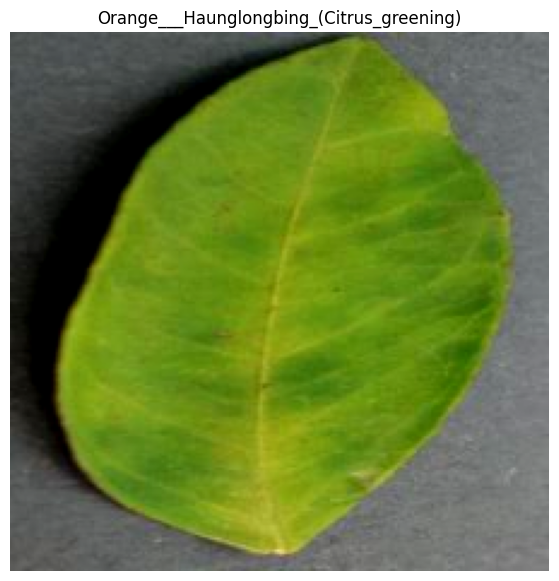

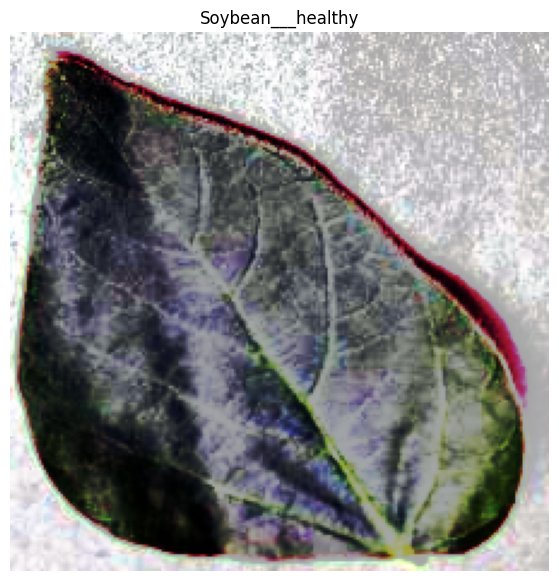

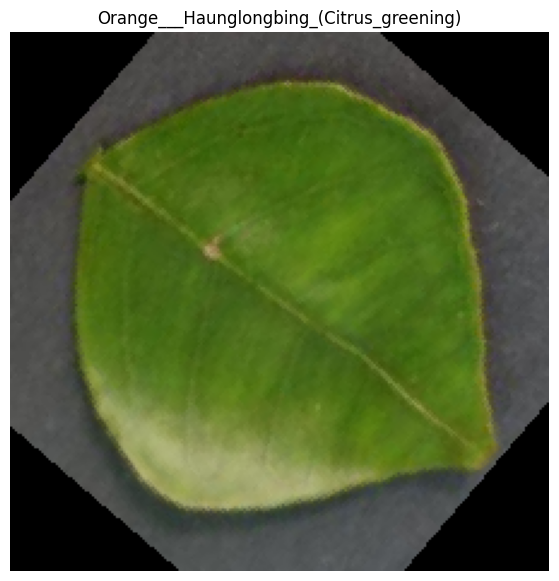

In [11]:
from utils import plot_transformed_images

plot_transformed_images(dataloader=train_dataloader, class_names=class_names, n=3, seed=42)

## 4. Model Training

In this section, we initialize a pretrained MobileNetV2 model, configure it for the plant disease classification task, and train it on the prepared dataset using transfer learning.

### 4.1. Build the Model

To improve code modularity and reusability, the model initialization is encapsulated in a helper function. This function loads a pretrained MobileNetV2 model, freezes the feature extraction layers, replaces the classifier to match the target number of classes, and optionally moves the model to the specified device.

The complete implementation is available in the project repository:

- **Source code:** https://github.com/qtrong0205/plant-care-ai-service/blob/main/classification/training/model_builder.py

In [12]:
from model_builder import build_model

model = build_model(num_classes=38, device=device)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 148MB/s]


### 4.2. Use `torchinfo` to get an idea of the shapes going through model

In [13]:
# Install torchinfo if it's not available, import it if it is
try:
    import torchinfo
except:
    !pip install torchinfo
    import torchinfo

from torchinfo import summary
summary(model, input_size=[32, 3, 224, 224]) # do a test pass through of an example input size

Layer (type:depth-idx)                             Output Shape              Param #
MobileNetV2                                        [32, 38]                  --
├─Sequential: 1-1                                  [32, 1280, 7, 7]          --
│    └─Conv2dNormActivation: 2-1                   [32, 32, 112, 112]        --
│    │    └─Conv2d: 3-1                            [32, 32, 112, 112]        (864)
│    │    └─BatchNorm2d: 3-2                       [32, 32, 112, 112]        (64)
│    │    └─ReLU6: 3-3                             [32, 32, 112, 112]        --
│    └─InvertedResidual: 2-2                       [32, 16, 112, 112]        --
│    │    └─Sequential: 3-4                        [32, 16, 112, 112]        (896)
│    └─InvertedResidual: 2-3                       [32, 24, 56, 56]          --
│    │    └─Sequential: 3-5                        [32, 24, 56, 56]          (5,136)
│    └─InvertedResidual: 2-4                       [32, 24, 56, 56]          --
│    │    └─Sequential

### 4.3. Configure the Training Pipeline

We define the loss function, optimizer, and other training configurations required for model optimization.

In [14]:
# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model.classifier.parameters(), lr=0.01, momentum=0.9)

### 4.4. Model Utilities

To keep the notebook concise and maintainable, the model construction and training utilities are implemented as reusable helper functions. These utilities include loading the pretrained MobileNetV2 model, configuring the classifier, and other functions used throughout the training pipeline.

The complete implementation can be found in the project repository:

- **Source code:** https://github.com/qtrong0205/plant-care-ai-service/blob/main/classification/training/engine.py

In [15]:
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

SUBSET_MODEL_PATH = MODEL_DIR / "subset.pth"
SUBSET_RESULTS_PATH = MODEL_DIR / "subset_results.pkl"

In [16]:
from engine import train
import pickle

if SUBSET_MODEL_PATH.exists() and SUBSET_RESULTS_PATH.exists():
    print("Loading subset model...")

    model.load_state_dict(torch.load(SUBSET_MODEL_PATH,
                                     map_location=device))
    model.eval()

    with open(SUBSET_RESULTS_PATH, "rb") as f:
        model_results = pickle.load(f)
else:
    print("Training subset model...")

    NUM_EPOCHS = 5

    model_results = train(
        model=model,
        train_dataloader=train_dataloader,
        test_dataloader=test_dataloader,
        loss_fn=loss_fn,
        optimizer=optimizer,
        epochs=NUM_EPOCHS,
        device=device
    )

    torch.save(model.state_dict(), SUBSET_MODEL_PATH)

    with open(SUBSET_RESULTS_PATH, "wb") as f:
        pickle.dump(model_results, f)

Loading subset model...


In [17]:
model_results

{'train_loss': [1.1811774736818146,
  0.6413729867952711,
  0.56180017364814,
  0.5248412967056912,
  0.48758664343725233],
 'train_acc': [0.6892233455882353,
  0.8161764705882353,
  0.8432904411764706,
  0.8461626838235294,
  0.8600643382352942],
 'test_loss': [0.42422277852892876,
  0.28895705611691536,
  0.19420291411156274,
  0.21584571726014154,
  0.2162938382342177],
 'test_acc': [0.8680847338935574,
  0.9038646708683473,
  0.940016631652661,
  0.9328825280112045,
  0.9285276610644257],
 'total_time': 187.299157116}

### 4.5. Visualize Training Results

Plotting the training loss and evaluation metrics to analyze the model's learning progress and overall performance.

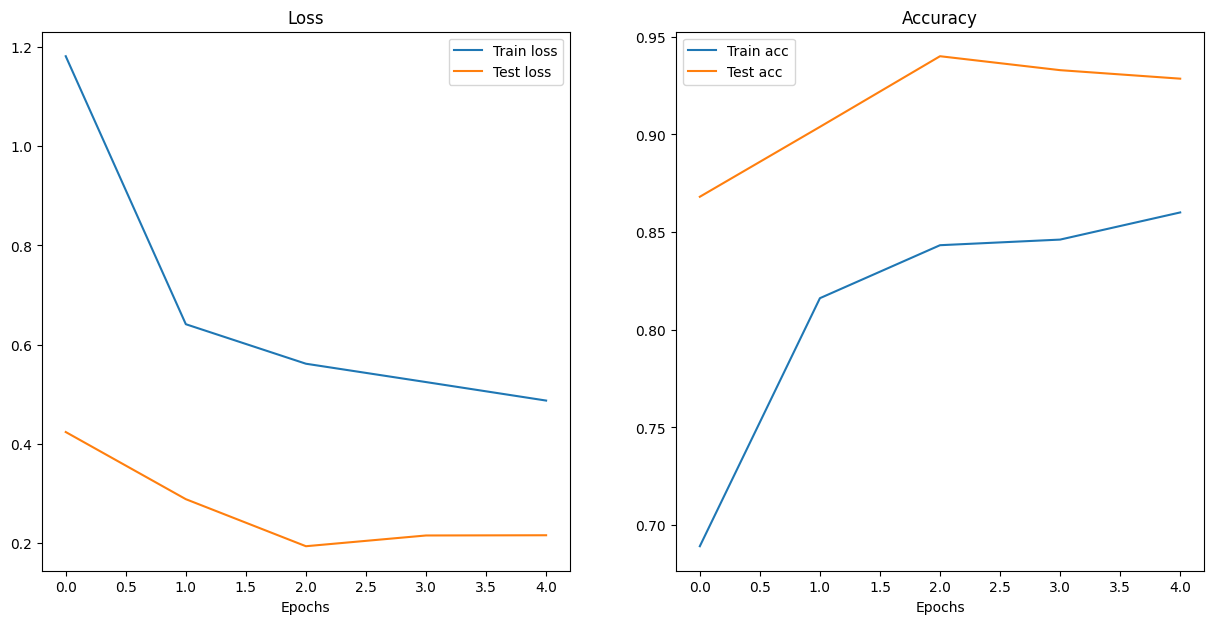

In [18]:
from utils import plot_loss_curves

plot_loss_curves(model_results)

## 5. Train with the Full Dataset

After validating the training pipeline and selecting the best hyperparameter configuration using a subset of the dataset, we retrain the model on the full PlantVillage dataset. This allows the model to learn from all available training samples and maximize its performance before deployment.

### 5.1. Recreate the Full Training Dataset

The training and testing datasets are recreated using the full PlantVillage dataset while keeping the same preprocessing pipeline and image transformations.

In [19]:
from data_setup import ImageDataset
from data_setup import create_dataloader

BATCH_SIZE = 32

# Create train and test dataset
train_dataset_full = ImageDataset(targ_dir=train_path,
                                  transform=train_transform,
                                  subset_ratio=1,
                                  seed=42)
test_dataset_full = ImageDataset(targ_dir=test_path,
                                 transform=test_transform,
                                 subset_ratio=1,
                                 seed=42)

# Create train and test dataloader
train_dataloader_full = create_dataloader(dataset=train_dataset_full,
                                          batch_size=BATCH_SIZE,
                                          num_workers=0,
                                          shuffle=True)
test_dataloader_full = create_dataloader(dataset=test_dataset_full,
                                         batch_size=BATCH_SIZE,
                                         num_workers=0,
                                         shuffle=False)

print(f"Total number of samples in train dataloader: {len(train_dataloader_full.dataset)}")
print(f"Total number of samples in test dataloader: {len(test_dataloader_full.dataset)}")

Total number of samples in train dataloader: 43429
Total number of samples in test dataloader: 10876


### 5.2. Train the Model on the Full Dataset

In [20]:
from model_builder import build_model

# Initialize a model
model_1 = build_model(num_classes=38, device=device)
model_1

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

In [21]:
# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.classifier.parameters(), lr=0.01, momentum=0.9)

In [22]:
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

FULLDATA_MODEL_PATH = MODEL_DIR / "fulldata.pth"
FULLDATA_RESULTS_PATH = MODEL_DIR / "fulldata_results.pkl"

In [23]:
from engine import train
import pickle

if FULLDATA_MODEL_PATH.exists() and FULLDATA_RESULTS_PATH.exists():
    print("Loading model trained with full dataset...")

    model_1.load_state_dict(torch.load(FULLDATA_MODEL_PATH,
                                     map_location=device))
    model_1.eval()

    with open(FULLDATA_RESULTS_PATH, "rb") as f:
        model_1_results = pickle.load(f)

else:
    print("Training model with full dataset...")

    NUM_EPOCHS = 5
    model_1_results = train(model=model_1,
                      train_dataloader=train_dataloader_full,
                      test_dataloader=test_dataloader_full,
                      loss_fn=loss_fn,
                      optimizer=optimizer,
                      epochs=NUM_EPOCHS,
                      device=device)

    torch.save(model_1.state_dict(), FULLDATA_MODEL_PATH)

    with open(FULLDATA_RESULTS_PATH, "wb") as f:
        pickle.dump(model_1_results, f)

Loading model trained with full dataset...


### 5.3. Visualize Training Results

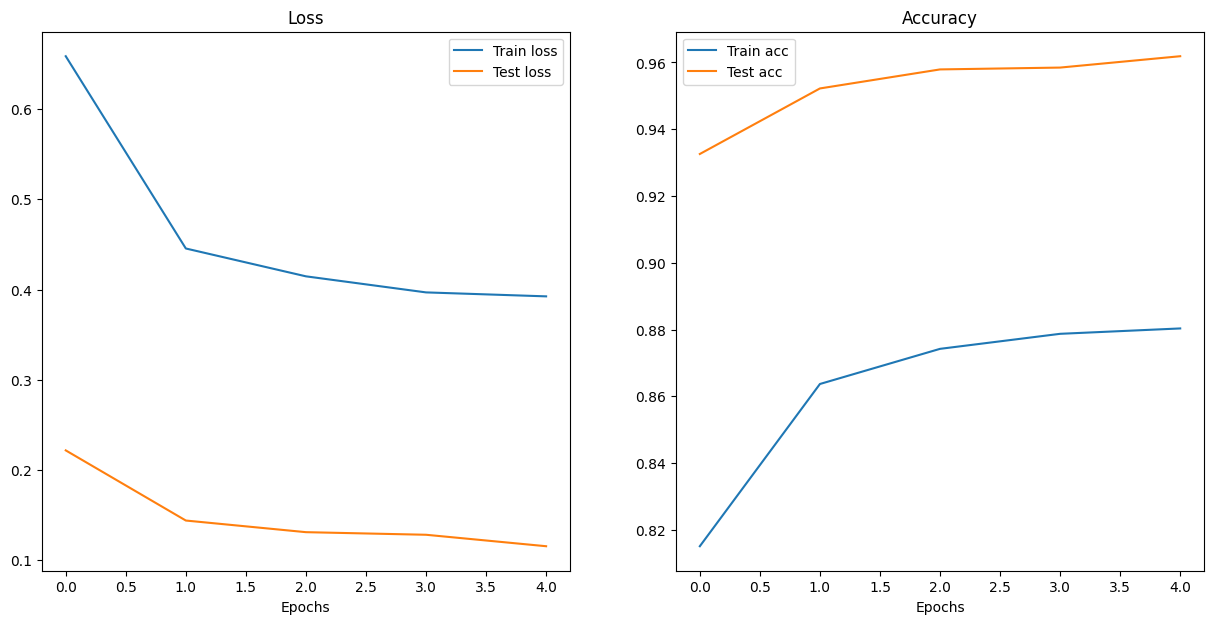

In [24]:
# Plot loss curve
plot_loss_curves(model_results=model_1_results)

In [36]:
def pred_and_plot_images(model,
                         dataset,
                         class_names,
                         device,
                         n: int = 5,
                         seed: int=None) -> None:
    """Predicts on random images from a dataset and plots them with
    predicted vs. true class labels.
    """
    if seed is not None:
        random.seed(seed)

    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(3,1,1)

    random_indices = random.sample(range(len(dataset)), k=n)

    # Making prediction
    model.eval()
    with torch.inference_mode():
        for i in random_indices:
            X, y = dataset[i]

            X = X.to(device)

            y_pred = model(X.unsqueeze(0))

            pred_class_idx = torch.argmax(y_pred, dim=1).item()
            probs = torch.softmax(y_pred, dim=1)

            pred_prob = probs.max(dim=1).values.item()
            pred_class = class_names[pred_class_idx]
            true_class = class_names[y]

            img_unnormalized = X * std + mean
            img_unnormalized = img_unnormalized.permute(1, 2, 0).clamp(0, 1).cpu()

            title = (
                f"True: {true_class}\n"
                f"Pred: {pred_class} ({pred_prob:.2%})\n"
                f"Shape: {X.unsqueeze(0).shape}"
                f"Type: {X.dtype}"
            )
            # Plotting predictions
            plt.figure(figsize=(12, 7))
            plt.imshow(img_unnormalized)
            plt.title(title, color="green" if true_class == pred_class else "red")
            plt.axis("off")

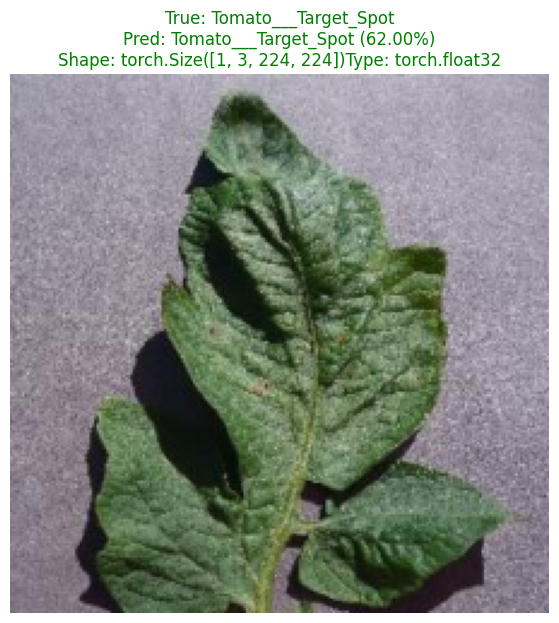

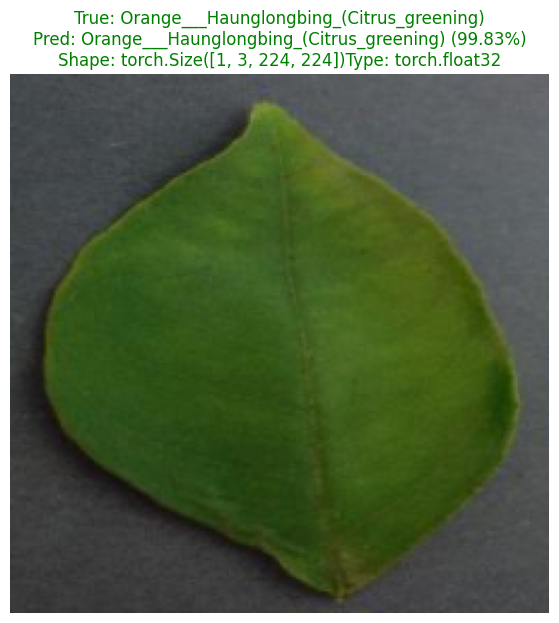

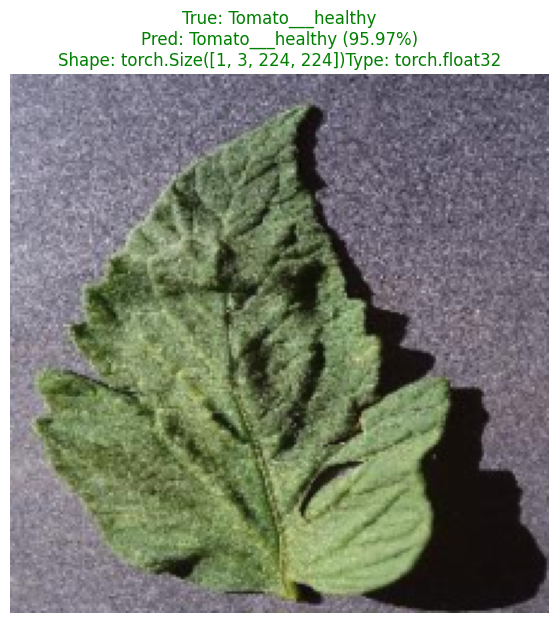

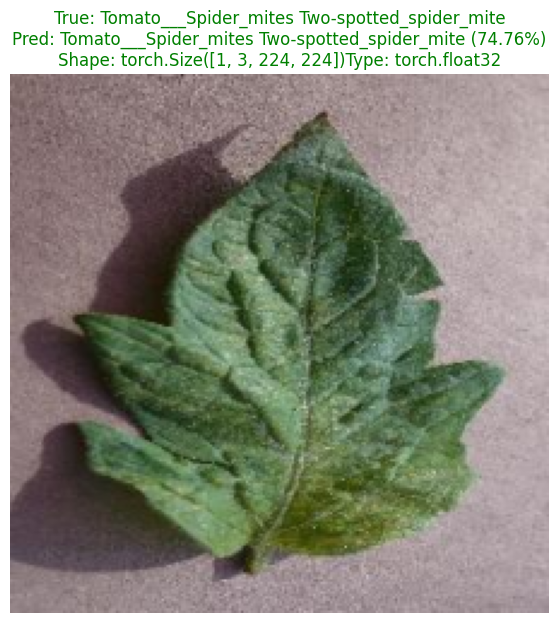

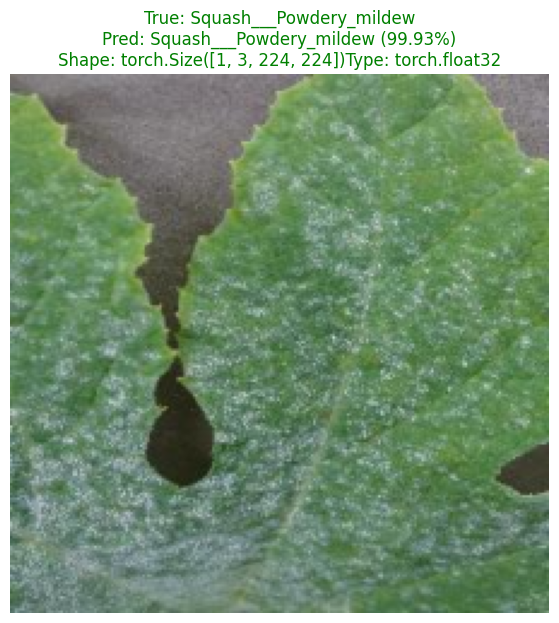

In [37]:
pred_and_plot_images(model=model_1,
                     dataset=test_dataset_full,
                     class_names=class_names,
                     device=device,
                     n=5,
                     seed=None)

## 6. Model Evaluation and Selection

In this section, we evaluate both the subset-trained model and the full-dataset model using **TorchMetrics**. By combining numerical metrics with qualitative prediction results, we compare the two models and select the most suitable one for deployment in the Plant Care Assistant application.

In [25]:
# Download and import libraries
try:
    import torchmetrics
except:
    !pip install -q torchmetrics
    import torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 23.6 MB/s eta 0:00:00


### 6.1. Accuracy Comparison

We compare the classification accuracy of both models on the test dataset to measure their overall predictive performance.

#### 6.1.1. Collect predictions

In [26]:
model.eval()

all_preds_subset = []
all_labels_subset = []

with torch.inference_mode():
    for X, y in test_dataloader:
        X, y = X.to(device), y.to(device)

        logits = model(X)
        preds = torch.argmax(logits, dim=1)

        all_preds_subset.append(preds)
        all_labels_subset.append(y)

all_preds_subset = torch.cat(all_preds_subset)
all_labels_subset = torch.cat(all_labels_subset)

In [27]:
model_1.eval()

all_preds_full = []
all_labels_full = []

with torch.inference_mode():
    for X, y in test_dataloader:
        X, y = X.to(device), y.to(device)

        logits = model_1(X)
        preds = torch.argmax(logits, dim=1)

        all_preds_full.append(preds)
        all_labels_full.append(y)

all_preds_full = torch.cat(all_preds_full)
all_labels_full = torch.cat(all_labels_full)

#### 6.1.2. Compute accuracy

In [28]:
from torchmetrics import Accuracy

accuracy = Accuracy(task="multiclass", num_classes=38).to(device)

subset_acc = accuracy(all_preds_subset, all_labels_subset)
full_acc = accuracy(all_preds_full, all_labels_full)

print(f"Accuracy of model trained with subset data: {subset_acc:.2f}")
print(f"Accuracy of model trained with full data: {full_acc:.2f}")

Accuracy of model trained with subset data: 0.93
Accuracy of model trained with full data: 0.97


### 6.2 Confusion matrix

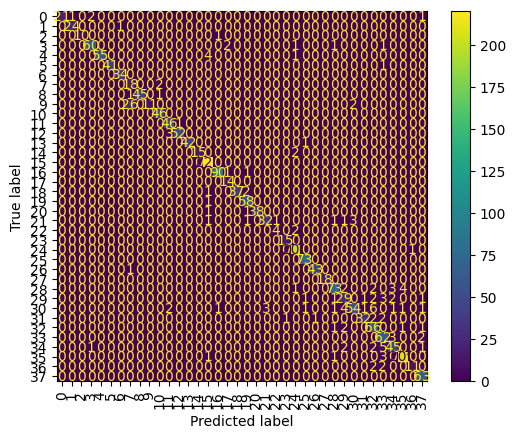

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

cm_subset = confusion_matrix(
    all_labels_subset.cpu(),
    all_preds_subset.cpu()
)

ConfusionMatrixDisplay(cm_subset).plot(
    xticks_rotation=90
)

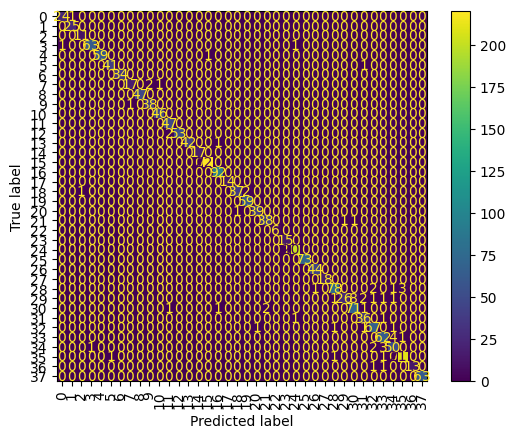

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

cm_full = confusion_matrix(
    all_labels_full.cpu(),
    all_preds_full.cpu()
)

ConfusionMatrixDisplay(cm_full).plot(
    xticks_rotation=90
)

### 6.4 Prediction on Random Test Images

We implemented a helper function to making predictions with model on on random images from a dataset and plots them with
predicted and true class labels.

The complete implementation can be found in the project repository:

- **Source code:** https://github.com/qtrong0205/plant-care-ai-service/blob/main/classification/training/utils.py

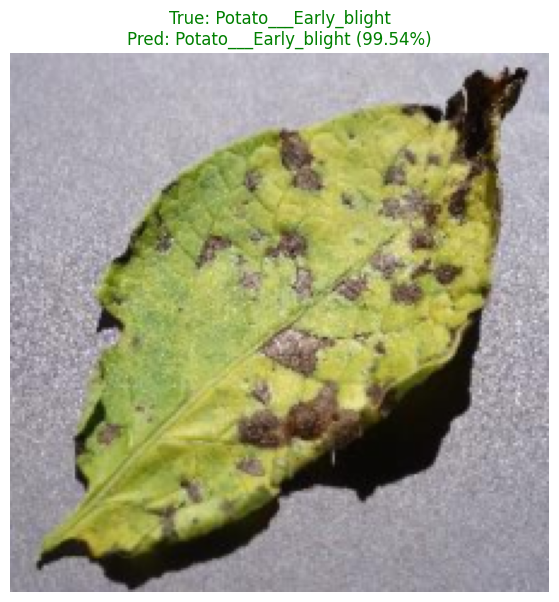

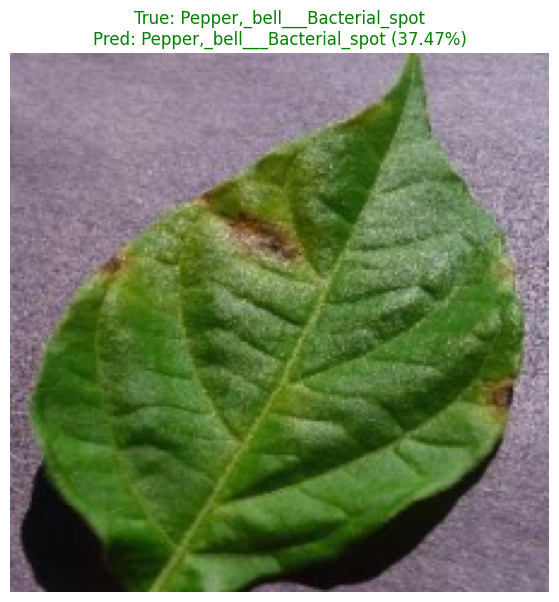

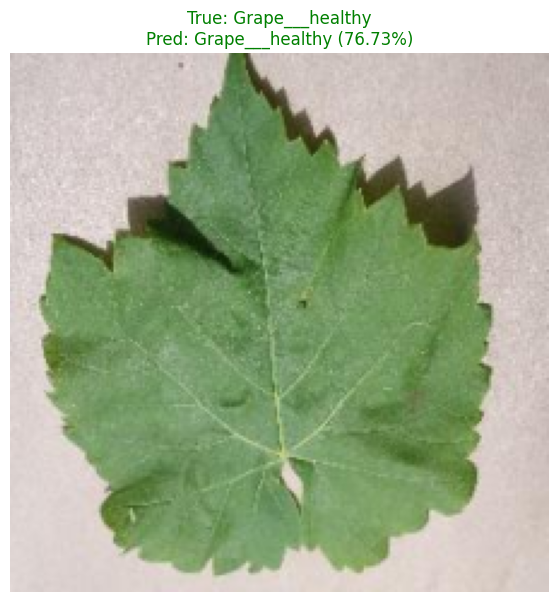

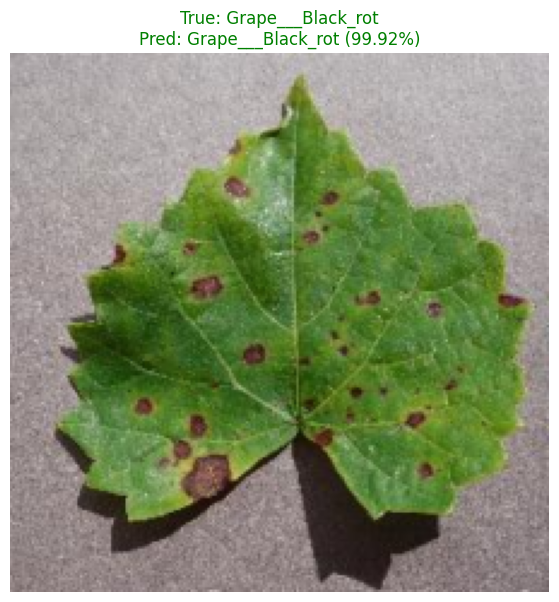

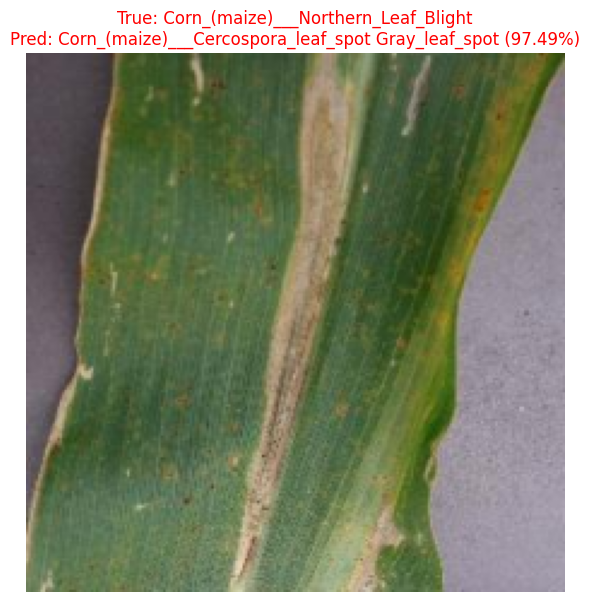

In [31]:
from utils import pred_and_plot_images

# Subset model
pred_and_plot_images(model=model,
                     dataset=test_dataset,
                     class_names=class_names,
                     device=device,
                     n=5,
                     seed=None)

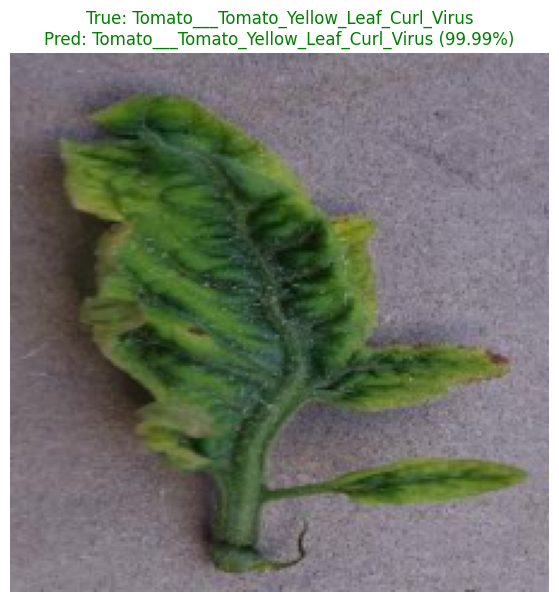

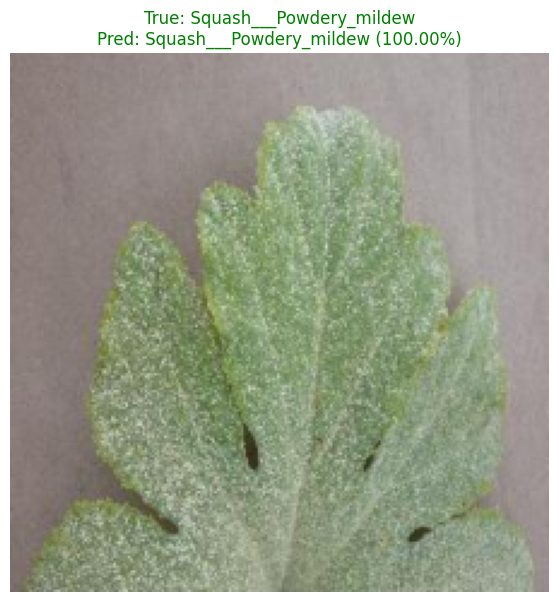

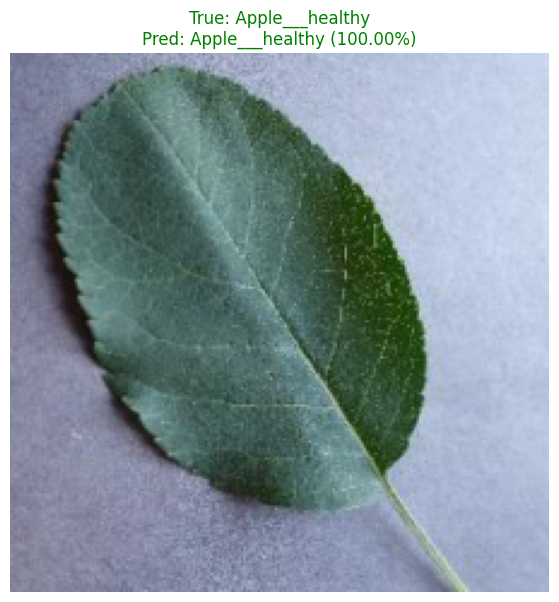

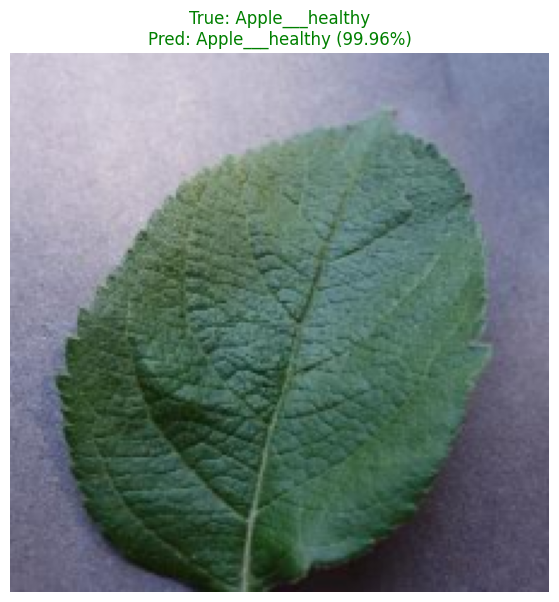

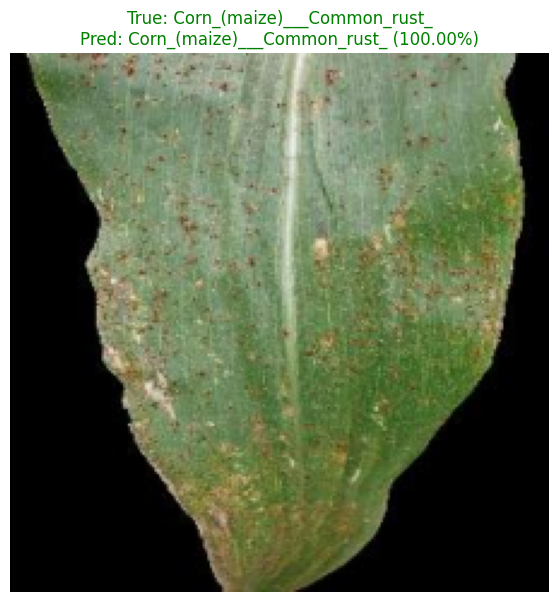

In [32]:
from utils import pred_and_plot_images

# Full data model
pred_and_plot_images(model=model_1,
                     dataset=test_dataset_full,
                     class_names=class_names,
                     device=device,
                     n=5,
                     seed=None)

### 6.5. Model Selection

Based on the evaluation results, the model trained on the **full PlantVillage dataset** was selected for deployment in the Plant Care Assistant application.

The decision is supported by the following observations:

- **Higher accuracy:** The full-dataset model achieved an accuracy of **96%**, outperforming the subset model, which achieved **93%**.
- **Better generalization:** Training on the complete dataset allows the model to learn from a larger and more diverse set of samples, resulting in better generalization to unseen images.
- **More reliable predictions:** During qualitative evaluation, the full-dataset model generally produced very high confidence scores for correctly classified images. In contrast, the subset model occasionally produced incorrect predictions with relatively high confidence (e.g., around **81%**), suggesting that it could be overconfident on some unseen samples.

Considering both the quantitative results and qualitative observations, the full-dataset model was selected as the final model for ONNX export and deployment.

## 7. Save Model

The selected model is exported to **ONNX format** for efficient inference and deployment in the Plant Care Assistant application.

In [39]:
!pip install onnxscript --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 722.0/722.0 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 83.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 17.9 MB/s eta 0:00:00


In [41]:
from pathlib import Path
from utils import export_to_onnx

Path("../model").mkdir(parents=True, exist_ok=True)

SAVE_PATH = "../model/model.onnx"
example_input = torch.rand((1, 3, 224, 224), dtype=torch.float32).to(device)

export_to_onnx(model=model_1,
               example_input=example_input,
               save_path=SAVE_PATH,
               input_names=["image"],
               output_names=["label"],
               dynamo=True)

[torch.onnx] Obtain model graph for `MobileNetV2([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV2([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Model exported to ../model/model.onnx
